# 02 - EDA

**Objetivo:** ver de qué hablan los tweets y qué eventos podrían aparecer, para tener **hipótesis concretas** que después se contrastan con BERTopic (04) y se validan con fuentes.

Esta notebook no modifica ni guarda datos. Usa los 1,6 M de tweets. Para contar palabras aplica solo la limpieza liviana de `utils.limpiar_texto`: sin URLs ni menciones y con las entidades HTML corregidas. Los filtros, la deduplicación y la muestra se deciden en la 03.

Qué responde:
1. ¿Qué tan largos son los tweets? ¿Están todos en inglés?
2. ¿Qué palabras, hashtags y menciones dominan?
3. ¿Qué pares de palabras forman expresiones con significado propio (**PMI**)?
4. ¿Qué palabras distinguen a cada día?
5. ¿Qué eventos candidatos hay y cuándo aparecen?

#### Dependencias

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
from langdetect import DetectorFactory, detect_langs
from nltk.collocations import BigramAssocMeasures, BigramCollocationFinder
from sklearn.feature_extraction.text import CountVectorizer

import utils

#### Parámetros

In [2]:
RANDOM_STATE = 42
N_IDIOMA = 3_000        # tweets para estimar el idioma
MIN_DF = 20             # vocabulario: palabras en al menos 20 tweets
MIN_FREQ_BIGRAMA = 200  # PMI favorece pares raros: se exige frecuencia mínima
MIN_TWEETS_DIA = 1_000  # días con menos tweets no se comparan (proporciones inestables)
MIN_PALABRA_DIA = 20    # una palabra cuenta para un día si aparece en 20 tweets o más

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 200)
sns.set_theme(style="whitegrid")
DetectorFactory.seed = 0  # langdetect es aleatorio: semilla fija

#### Funciones

In [3]:
def top_items(listas, n):
    """Elementos más frecuentes en una serie de listas (hashtags, menciones)."""
    return pd.Series(Counter(x.lower() for l in listas for x in l)).nlargest(n)


def idioma(texto):
    """Idioma más probable según langdetect y su probabilidad."""
    try:
        r = detect_langs(texto)[0]
        return r.lang, r.prob
    except Exception:  # textos sin letras
        return "?", 0.0

## 1. Carga

- Se quitan los 1.685 ids repetidos detectados en la 01 (misma fila con polaridad opuesta).
- `texto_limpio` queda en minúsculas y se usa para contar palabras.
- Para los conteos se usa una sola copia de cada texto limpio (`unicos`), así las plantillas de bots y las frases repetidas no inflan las frecuencias.

In [4]:
df = utils.leer_tweets(utils.FILE_TRAIN).drop_duplicates("id")
df["fecha_pdt"] = utils.parsear_fecha(df["fecha"])
df["dia"] = df["fecha_pdt"].dt.normalize()
df["texto_limpio"] = utils.limpiar_texto(df["texto"]).str.lower()

unicos = df.drop_duplicates("texto_limpio")
print(f"Tweets (ids únicos):    {len(df):>9,}")
print(f"Textos limpios únicos:  {len(unicos):>9,}  ({1 - len(unicos) / len(df):.1%} repetidos)")

Tweets (ids únicos):    1,598,315
Textos limpios únicos:  1,541,023  (3.6% repetidos)


## 2. Largo de los tweets

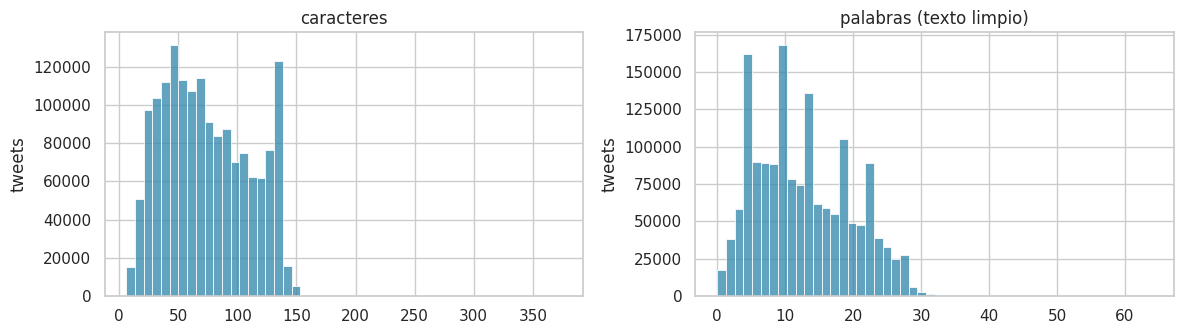

,count,mean,std,min,25%,50%,75%,max
caracteres,1598315.0,74.1,36.4,6.0,44.0,69.0,104.0,374.0
palabras (texto limpio),1598315.0,12.6,7.0,0.0,7.0,12.0,18.0,64.0


In [5]:
largo = pd.DataFrame({
    "caracteres": df["texto"].str.len(),
    "palabras (texto limpio)": df["texto_limpio"].str.split().str.len(),
})

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, col in zip(axes, largo.columns):
    sns.histplot(largo[col], bins=50, ax=ax, color="#2e86ab")
    ax.set(title=col, xlabel="", ylabel="tweets")
plt.tight_layout()
plt.show()

largo.describe().round(1).T

In [6]:
pal = largo["palabras (texto limpio)"]
for n in [1, 2, 3]:
    print(f"Menos de {n + 1} palabras: {(pal <= n).mean():.1%}")
df.loc[pal < 3, "texto"].sample(10, random_state=RANDOM_STATE).tolist()

Menos de 2 palabras: 1.1%
Menos de 3 palabras: 3.4%
Menos de 4 palabras: 7.1%


[' &lt;*~Free!~*&gt;',
 'Eattin lunch ',
 'ughh............neeeeedddd job.......... ',
 'SUMMER HOLZ!! ',
 '@ClassikBeats Good luck ',
 '@vanewpc Thank you ',
 "I'm yours ",
 '@msajamarie follow me ',
 'boreeed!! ',
 '@KristinaThinks ']

- Mediana de **12 palabras**: cada tweet tiene muy poco contexto.
- El **3,4%** tiene menos de 3 palabras después de limpiar (`headache`, `at work`). No dicen de qué tema se habla → se filtran en la 03.

## 3. Idioma

Sentiment140 debería estar en inglés. Se estima con `langdetect` sobre una muestra.

In [7]:
muestra = df.sample(N_IDIOMA, random_state=RANDOM_STATE)
idiomas = pd.DataFrame(muestra["texto_limpio"].map(idioma).tolist(),
                       columns=["idioma", "prob"], index=muestra.index)
idiomas["texto"] = muestra["texto_limpio"]
print(f"Detectados como no inglés: {(idiomas['idioma'] != 'en').mean():.1%}")
idiomas["idioma"].value_counts().head(8)

Detectados como no inglés: 9.8%


idioma
en    2707
af      38
so      35
cy      31
no      30
tl      21
fr      14
hr      12
Name: count, dtype: int64

In [8]:
idiomas[idiomas["idioma"] != "en"].sample(20, random_state=1)

,idioma,prob,texto
1312391,sq,0.857141,shake shake shake shake a shake it...
588211,fr,0.999997,ouch
4736,so,0.999996,bad dayy
821609,et,0.714283,im on msn
664479,no,0.571426,is gonna sing. paramoreee ! i guess i will play the drums i suckkkkkkkkkkkkk (:
13737,cy,0.999997,here we go againn....
835532,so,0.714284,ahahahahaha loser... i make better sandwiches
263230,cy,0.714283,i miss my boys.
382877,hu,0.999996,lend me a razor.
276041,so,0.428571,monday shmonday...blahhh long week ahead


- `langdetect` marca un 10% como no inglés, pero los 20 casos de arriba **están todos en inglés**: son frases cortas (`ouch`, `bad dayy`), con letras repetidas o con jerga. El detector no funciona bien con textos tan cortos.
- Filtrar con `langdetect` borraría muchos tweets en inglés. **No se filtra por idioma.** Si quedan tweets en otro idioma, deberían agruparse en un tópico aparte, fácil de reconocer en la 04.

## 4. Palabras más frecuentes

Vocabulario: 21,649 palabras en al menos 20 tweets


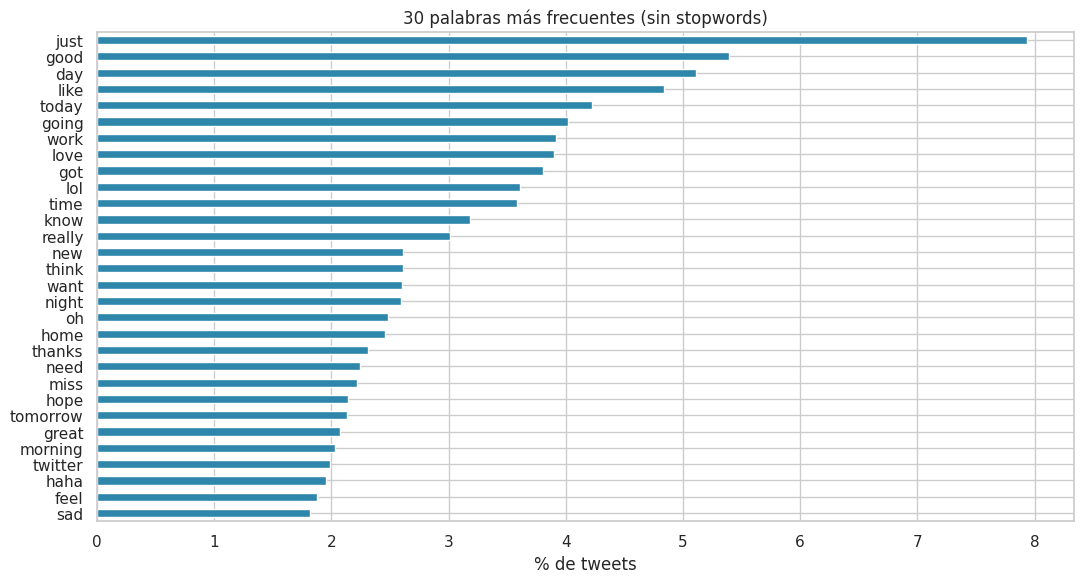

In [9]:
cv = CountVectorizer(stop_words=utils.STOPWORDS, token_pattern=utils.TOKEN_PATTERN,
                     min_df=MIN_DF, binary=True)
X = cv.fit_transform(unicos["texto_limpio"])  # tweets x palabras (1 si aparece)
vocab = cv.get_feature_names_out()
doc_freq = pd.Series(np.asarray(X.sum(axis=0)).ravel(), index=vocab)
print(f"Vocabulario: {len(vocab):,} palabras en al menos {MIN_DF} tweets")

top30 = doc_freq.nlargest(30) / len(unicos) * 100
fig, ax = plt.subplots(figsize=(11, 6))
top30.sort_values().plot.barh(ax=ax, color="#2e86ab")
ax.set(title="30 palabras más frecuentes (sin stopwords)", xlabel="% de tweets")
plt.tight_layout()
plt.show()

- Dominan palabras de **la vida diaria y el estado de ánimo**: `good`, `day`, `work`, `love`, `today`, `miss`, `sleep`, `sad`.
- Confirma el sesgo de la recolección por emoticones: la mayoría son tweets personales. Un modelo de tópicos va a encontrar sobre todo temas cotidianos (trabajo, sueño, clima, saludos). Los eventos van a ser tópicos chicos.

## 5. Hashtags y menciones

In [10]:
limpio_html = df["texto"].str.replace("ï¿½", "'", regex=False)
hashtags = top_items(limpio_html.str.findall(r"#(\w+)"), 25)
menciones = top_items(limpio_html.str.findall(r"@(\w+)"), 25)

pd.concat([
    hashtags.rename_axis("hashtag").reset_index(name="tweets"),
    menciones.rename_axis("mención").reset_index(name="tweets"),
], axis=1)

,hashtag,tweets,mención,tweets
0,followfriday,2638,mileycyrus,4562
1,fb,1783,tommcfly,3890
2,ff,985,ddlovato,3469
3,squarespace,940,jonasbrothers,2380
4,1,519,davidarchie,1382
5,iranelection,518,donniewahlberg,1330
6,seb,499,jonathanrknight,1263
7,musicmonday,421,jordanknight,1150
8,fail,363,mitchelmusso,1100
9,2,341,taylorswift13,1026


- **Hashtags:** hay convenciones de Twitter (`followfriday`, `ff`, `fb`, `musicmonday`), concursos (`squarespace`) y algunos eventos (`iranelection`, `e3`, `bgt`, `asot400`, `f1`). Solo el ~2% de los tweets usa hashtags: no alcanzan para encontrar temas.
- **Menciones:** dominan **cantantes y actores** (Miley Cyrus, McFly, Demi Lovato, Jonas Brothers). Es esperable un tópico de *fans* que les escriben.

## 6. Expresiones de dos palabras: frecuencia vs PMI

Contar bigramas devuelve frases comunes. La **PMI** (*pointwise mutual information*) mide cuánto más aparecen dos palabras juntas que lo esperado si fueran independientes:

$$\text{PMI}(x, y) = \log_2 \frac{P(x, y)}{P(x)\,P(y)}$$

- PMI alta → la pareja funciona como una unidad: nombres propios, títulos, productos.
- Con pocas apariciones la PMI se infla (dos palabras raras que coinciden una vez tienen PMI altísima) → se exige una frecuencia mínima.
- Se cuentan pares dentro de un mismo tweet y se descartan los que incluyen stopwords.

In [11]:
tokens = unicos["texto_limpio"].str.findall(r"[a-z][a-z0-9']+")
finder = BigramCollocationFinder.from_documents(tokens.tolist())
stop = set(utils.STOPWORDS)
finder.apply_word_filter(lambda w: w in stop or len(w) < 3)
finder.apply_ngram_filter(lambda a, b: a == b)  # `delongeday delongeday`
finder.apply_freq_filter(MIN_FREQ_BIGRAMA)

medidas = BigramAssocMeasures()
por_pmi = finder.score_ngrams(medidas.pmi)[:30]
por_freq = finder.ngram_fd.most_common(30)

pd.DataFrame({
    "por frecuencia": [" ".join(b) for b, _ in por_freq],
    "veces": [n for _, n in por_freq],
    "por PMI": [" ".join(b) for b, _ in por_pmi],
    "PMI": [round(s, 1) for _, s in por_pmi],
    "veces ": [finder.ngram_fd[b] for b, _ in por_pmi],
})

,por frecuencia,veces,por PMI,PMI,veces
0,just got,11153,pushing daisies,15.2,227
1,good morning,8525,farrah fawcett,15.0,334
2,feel like,6457,robert pattinson,14.5,204
3,looking forward,5492,britney spears,14.4,203
4,looks like,5122,susan boyle,14.3,550
5,getting ready,4775,peanut butter,14.2,354
6,good luck,4761,lines vines,14.2,310
7,good night,4311,harry potter,14.0,673
8,good day,3744,hip hop,13.9,215
9,great day,3299,taco bell,13.9,268


- **Por frecuencia** salen frases de la vida diaria (`just got`, `good morning`, `feel like`). Solo `new moon` (la secuela de *Crepúsculo*) apunta a un tema concreto.
- **Por PMI** salen **entidades**: personas (`farrah fawcett`, `susan boyle`, `david carradine`), películas y series (`star trek`, `harry potter`, `pushing daisies`), productos y marcas (`palm pre`, `taco bell`), lugares (`san diego`) y eventos (`swine flu`, `american idol`). También expresiones fijas (`peanut butter`, `fingers crossed`, `wisdom teeth`).
- La PMI sirve para **encontrar candidatos a tópicos**. Más adelante se usa su versión normalizada (NPMI, entre -1 y 1) para medir la **coherencia** de los tópicos.

## 7. Qué palabras distinguen a cada día

Misma idea aplicada a palabra y día: ¿cuánto más aparece una palabra ese día que en todo el período?

$$\text{PMI}(\text{palabra}, \text{día}) = \log_2 \frac{P(\text{palabra} \mid \text{día})}{P(\text{palabra})}$$

- $P$ = proporción de tweets que contienen la palabra. Al ser una **proporción**, no importa que los días tengan volúmenes distintos.
- Se exige que la palabra aparezca en al menos 20 tweets ese día, y se omiten los días con menos de 1.000 tweets (23, 25 y 27/5).

In [12]:
dias = unicos["dia"].to_numpy()
dias_unicos, idx_dia = np.unique(dias, return_inverse=True)
# matriz días x tweets para sumar la matriz tweets x palabras por día
D = sp.csr_matrix((np.ones(len(unicos)), (idx_dia, np.arange(len(unicos)))),
                  shape=(len(dias_unicos), len(unicos)))
conteo_dia = (D @ X).toarray()               # tweets de cada día que contienen cada palabra
tweets_dia = np.bincount(idx_dia)
p_global = doc_freq.to_numpy() / len(unicos)

filas = []
for i, dia in enumerate(pd.to_datetime(dias_unicos)):
    if tweets_dia[i] < MIN_TWEETS_DIA:
        continue
    pmi = np.log2(conteo_dia[i] / tweets_dia[i] / p_global, where=conteo_dia[i] > 0,
                  out=np.full(len(vocab), -np.inf))
    pmi[conteo_dia[i] < MIN_PALABRA_DIA] = -np.inf
    top = np.argsort(-pmi)[:8]
    filas.append({"día": dia.strftime("%a %d/%m"), "tweets": tweets_dia[i],
                  "palabras características": ", ".join(vocab[top])})

pd.DataFrame(filas)

,día,tweets,palabras características
0,Mon 06/04,3297,"season, break, goodnight, tweets, sweet, bed, late, crazy"
1,Tue 07/04,17009,"snowing, easter, snow, april, spring, holidays, italy, winter"
2,Fri 17/04,3030,"lonely, friday, goodnight, cute, hit, bed, girls, welcome"
3,Sat 18/04,21284,"asot400, coachella, ipl, yankees, easter, oprah, spring, female"
4,Sun 19/04,26811,"asot400, vettel, easter, coachella, ipl, ferrari, trance, f1"
5,Mon 20/04,17874,"oracle, tweetie, easter, mondays, spring, april, presentation, holidays"
6,Tue 21/04,8311,"tweetie, uni, shining, sunshine, design, australia, office, sunny"
7,Fri 01/05,7446,"wolverine, swine, flu, men, followfriday, hanging, goodnight, movies"
8,Sat 02/05,26675,"awaresg, bamboozle, hatton, pacquiao, derby, wolverine, origins, kentucky"
9,Sun 03/05,34339,"logies, logie, hoppusday, hatton, pacquiao, pacman, bamboozle, cook's"


- Casi todos los días tienen palabras que remiten a **algo puntual**: fechas especiales (`easter`, `mother's`, `fathers`), deportes (`pacquiao`, `hatton`, `f1`, `facup`, `lakers`), TV (`gokey`, `archuleta`, `eurovision`, `diversity`), tecnología (`oracle`, `e3`, `natal`, `os3`, `tethering`, `jailbreak`), noticias y política (`af447`, `passengers`, `eu09`, `bnp`, `iranelection`, `tehran`) y muertes de famosos (`carradine`, `mcmahon`, `fawcett`).
- También aparecen campañas de fans (`andyhurleyday`, `delongeday`, `marsiscoming`) y juegos de hashtags (`iremember`, `haveyouever`, `inaperfectworld`). Son picos reales en Twitter, pero no son eventos externos.
- Los días con pocos tweets (6/4, 17/4, 21/5) muestran sobre todo palabras cotidianas.

## 8. Evolución de los eventos candidatos

Términos tomados de las secciones 6 y 7. Para cada día: tweets que los mencionan cada 10.000 tweets del día. El color está normalizado por fila (1 = día de máximo de ese término) para ver **cuándo** aparece cada uno.

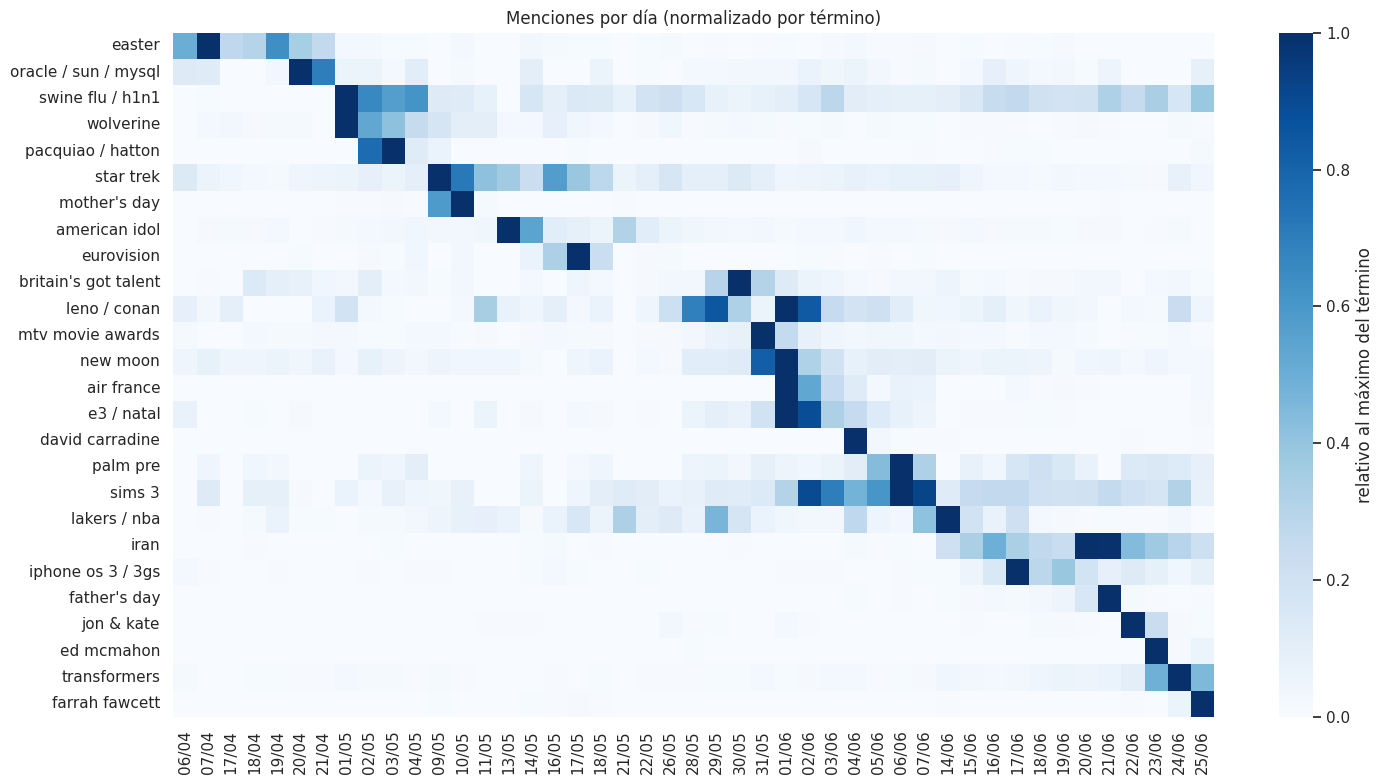

In [13]:
CANDIDATOS = {
    "easter": r"\beaster\b",
    "oracle / sun / mysql": r"\boracle\b|\bmysql\b",
    "swine flu / h1n1": r"\bswine\b|h1n1",
    "wolverine": r"wolverine",
    "pacquiao / hatton": r"pacquiao|\bhatton\b",
    "star trek": r"star ?trek",
    "mother's day": r"mother'?s'? ?day",
    "american idol": r"american idol|\bgokey\b|archuleta|kris allen",
    "eurovision": r"eurovision",
    "britain's got talent": r"susan boyle|\bbgt\b|got talent",
    "leno / conan": r"\bleno\b|\bconan\b",
    "mtv movie awards": r"\bmtv\b",
    "new moon": r"new moon",
    "air france": r"air ?france|\baf ?447\b",
    "e3 / natal": r"\be3\b|project natal",
    "david carradine": r"carradine",
    "palm pre": r"palm pre",
    "sims 3": r"\bsims\b",
    "lakers / nba": r"\blakers?\b|nba final",
    "iran": r"\biran|tehran|\bneda\b",
    "iphone os 3 / 3gs": r"\bos ?3(?:\.0)?\b|iphone 3\.0|\b3gs\b",
    "father's day": r"father'?s'? ?day",
    "jon & kate": r"jon (?:&|and) kate|gosselin",
    "ed mcmahon": r"mcmahon",
    "transformers": r"transformers",
    "farrah fawcett": r"farrah|fawcett",
}

validos = unicos[unicos.groupby("dia")["dia"].transform("size") >= MIN_TWEETS_DIA]
tasa = pd.DataFrame({
    nombre: validos["texto_limpio"].str.contains(patron).groupby(validos["dia"]).mean() * 10_000
    for nombre, patron in CANDIDATOS.items()
}).T
tasa.columns = tasa.columns.strftime("%d/%m")

fig, ax = plt.subplots(figsize=(15, 8))
sns.heatmap(tasa.div(tasa.max(axis=1), axis=0), cmap="Blues", cbar_kws={"label": "relativo al máximo del término"}, ax=ax)
ax.set(title="Menciones por día (normalizado por término)", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

In [14]:
pico = pd.DataFrame({
    "día del pico": tasa.idxmax(axis=1),
    "cada 10 mil (pico)": tasa.max(axis=1).round(1),
    "cada 10 mil (mediana)": tasa.median(axis=1).round(1),
    "tweets totales": [unicos["texto_limpio"].str.contains(p).sum() for p in CANDIDATOS.values()],
})
pico["pico / mediana"] = (pico["cada 10 mil (pico)"] / pico["cada 10 mil (mediana)"].clip(lower=0.1)).round(0)
pico

,día del pico,cada 10 mil (pico),cada 10 mil (mediana),tweets totales,pico / mediana
easter,07/04,60.6,0.5,381,121.0
oracle / sun / mysql,20/04,24.1,0.6,175,40.0
swine flu / h1n1,01/05,61.8,8.2,1535,8.0
wolverine,01/05,94.0,1.5,589,63.0
pacquiao / hatton,03/05,27.4,0.0,166,274.0
star trek,09/05,88.8,6.2,1376,14.0
mother's day,10/05,898.4,0.4,3032,2246.0
american idol,13/05,171.8,3.9,930,44.0
eurovision,17/05,51.6,0.0,295,516.0
britain's got talent,30/05,97.9,2.7,1953,36.0


- La mayoría de los términos tiene **un pico de uno o dos días** y casi nada el resto del período: el patrón típico de un evento.
- Otros tienen **presencia sostenida** con picos: `swine flu` (desde el 1/5 hasta el final), `iran` (desde el 15/6, máximo el 20–21/6), `lakers` (playoffs, máximo el 14/6) y `sims` (2–7/6).
- Que un término tenga un pico **no confirma** el evento: solo indica que vale la pena buscarlo. La validación con fuentes va en la 04, junto al tópico que encuentre BERTopic.

## 9. Hipótesis de eventos para validar

| Evento candidato | Fechas en los datos | Evidencia en esta notebook |
| --- | --- | --- |
| Pascua | 7 y 18–20/4 | `easter` (secc. 7 y 8) |
| Oracle compra Sun Microsystems | 20/4 | `oracle`, `mysql` (secc. 7) |
| Gripe porcina (H1N1) | desde el 1/5 (máximo ese día) | `swine flu` (PMI), `h1n1` |
| Estreno de *X-Men Origins: Wolverine* | 1–3/5 | `wolverine` |
| Pelea Pacquiao–Hatton | 2–3/5 | `pacquiao`, `hatton` |
| Estreno de *Star Trek* | 9–18/5 | `star trek` (PMI) |
| Día de la Madre (EE. UU.) | 9–10/5 | `mother's` |
| Eliminación de Danny Gokey en *American Idol* | 13–14/5 | `gokey`, `kris`, `adam`, `finale` |
| Final de Eurovisión | 16–17/5 | `eurovision`, `norway` |
| Lanzamiento de Wolfram Alpha | 18/5 | `wolfram`, `wolframalpha` (secc. 7) |
| Final de *Britain's Got Talent* | 30/5 | `diversity`, `susan boyle`, `stavros flatley` |
| MTV Movie Awards y tráiler de *New Moon* | 31/5–1/6 | `mtv`, `awards`, `trailer`, `new moon` |
| Desaparición del vuelo Air France 447 | 1–2/6 | `france`, `atlantic`, `passengers` |
| E3: Project Natal, Nintendo, Sony | 1–2/6 | `e3`, `xboxe3`, `natal` |
| Despedida de Leno y debut de Conan en *The Tonight Show* | 29/5–2/6 | `leno`, `conan` |
| Muerte de David Carradine | 4/6 | `carradine` (PMI y secc. 7) |
| Lanzamiento de *Los Sims 3* y del Palm Pre | 2–7/6 | `sims`, `palm pre` |
| Elecciones al Parlamento Europeo | 7/6 | `eu09`, `bnp`, `mep` (secc. 7) |
| Final de la NBA (Lakers) | 14–17/6 | `lakers`, `parade` |
| Elecciones y protestas en Irán | desde el 15/6, máximo 20–21/6 | `iranelection`, `tehran`, `neda` |
| iPhone OS 3.0 y iPhone 3GS | 17–19/6 | `os`, `mms`, `tethering`, `jailbreak` |
| Día del Padre (EE. UU.) | 20–21/6 | `fathers` |
| Divorcio de Jon y Kate Gosselin | 22–23/6 | `jon`, `kate`, `divorce` |
| Muerte de Ed McMahon | 23/6 | `mcmahon` |
| Estreno de *Transformers 2* | 23–25/6 | `transformers` |
| Muerte de Farrah Fawcett | 25/6 | `farrah fawcett` (PMI y secc. 7) |

## 10. Conclusiones del EDA

| Hallazgo | Decisión |
| --- | --- |
| Domina la charla personal (trabajo, sueño, ánimo) | Esperar muchos tópicos cotidianos. Los eventos se buscan entre tópicos chicos y con picos en el tiempo |
| 3,4% de tweets con menos de 3 palabras | 03: se filtran |
| 3,6% de textos repetidos tras limpiar | 03: deduplicar sobre el texto limpio |
| `langdetect` falla con textos cortos; casi todo es inglés | No se filtra por idioma |
| Hashtags en solo ~2% de los tweets | Se conservan como palabras (`#e3` → `e3`), pero no alcanzan para definir temas |
| Menciones a famosos muy frecuentes | Se quitan del texto: identifican a quién se le escribe, no de qué se habla. Es esperable un tópico de fans |
| PMI de bigramas recupera entidades | Usar bigramas en el vectorizador de BERTopic y en KeyBERT; NPMI como métrica de coherencia |
| PMI palabra–día detecta eventos puntuales | Lista de 26 hipótesis para contrastar con los tópicos y validar con fuentes |
| Volumen diario desparejo | Comparar tópicos en el tiempo con proporciones, no con conteos |